<a href="https://colab.research.google.com/github/sofiajaimesbarajas-lgtm/Estad-stica-1-/blob/main/ESTADISTICA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Estadística descriptiva para variables cuantitativas**
- Gráficos para datos univariados cuantitativos.
- Determinar las medidas descriptivas para datos univariados cuantitativos.

Estudiantes:

Andrea Catalina Jaimes Rodriguez 2241878
Valery Sofia Jaimes Barajas 2240990

In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded=files.upload()


Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


In [11]:
import pandas as pd
import io
from google.colab import files
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep=",", index_col=0, encoding='latin-1')
tabla.head(3)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1


In [14]:
df= tabla[["EDAD_PADRE","N_EMB"]]
df.head(3)

,EDAD_PADRE,N_EMB
COD_DPTO,,
76,39,2
19,27,3
41,28,3


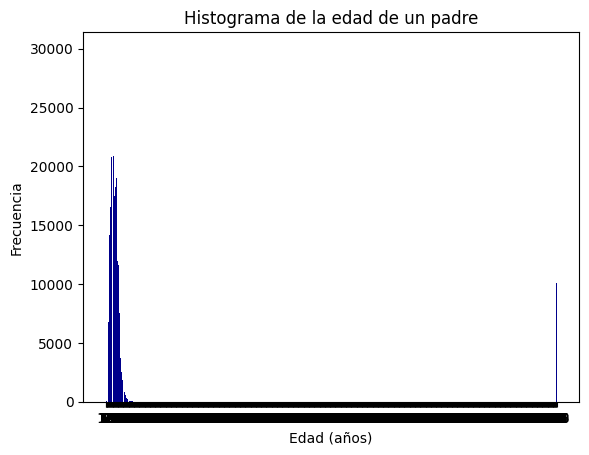

In [12]:
import matplotlib.pyplot as plt
# Asegurar que df está definido usando la variable global si es necesario
intervalos = range(min(df.EDAD_PADRE), max(df.EDAD_PADRE) + 1)
plt.hist(df.EDAD_PADRE, bins=intervalos, color="darkblue", rwidth=0.85)
plt.title("Histograma de la edad de un padre")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia")
plt.xticks(intervalos)
plt.show()

In [15]:
df1 = df[(df.EDAD_PADRE < 120) & (df.N_EMB != 99)]
df1.head(5)

,EDAD_PADRE,N_EMB
COD_DPTO,,
76,39,2
19,27,3
41,28,3
50,27,1
50,31,5


/tmp/ipykernel_2751/1839237827.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(x, p, 'k', linewidth=2, label='Distribución Normal', color = "darkblue")


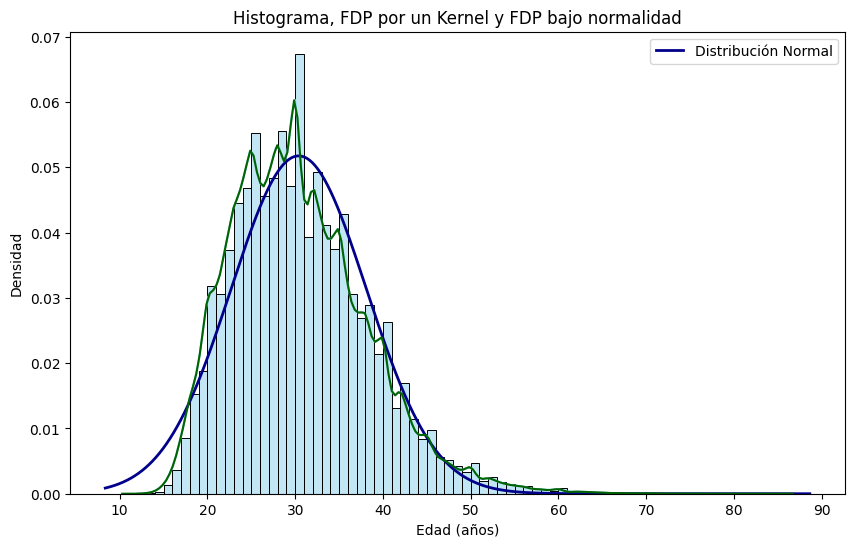

In [ ]:
import matplotlib.pyplot as plot
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) + 1)
plot.figure(figsize=(10, 6))
sns.histplot(x = df1.EDAD_PADRE, bins = intervalos1, kde = True, stat = "density", color = "skyblue", edgecolor='black') # kde = True es la gráfica de la función de densidad de probabilidad estimada por un método Kernel



xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))


p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

plt.plot(x, p, 'k', linewidth=2, label='Distribución Normal', color = "darkblue")
sns.kdeplot(x=df1.EDAD_PADRE, color = "darkgreen")

plt.title('Histograma, FDP por un Kernel y FDP bajo normalidad')
plt.xlabel('Edad (años)')
plt.ylabel('Densidad')
plt.legend()

Sea $X :=$ Edad del padre de un recién nacido en Colombia.

Descriptivamente como la función de densidad de probabilidad de los datos estimada por un método Kernel (línea cyan) no coincide con la función de densidad de probabilidad asumiendo el supuesto de normalidad (línea azul), $X \sim Normal(Media = \bar{x}, Varianza = S_x^2)$, entonces no asumimos normalidad


In [ ]:
from scipy.stats import shapiro
shapiro(df1.EDAD_PADRE)


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443777.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9677117198585043), pvalue=np.float64(7.6156069148173195e-109))

Si el Valor p en una prueba de hipótesis es menor
que 0.05 se rechaza la hipótesis nula con una confianza del 95%.
Si el Valor p es una prueba de hipótesis es mayor que 0.05 no se rechaza la hipótesis nula con una confianza del 95%.
En nuestro caso particular, tenemos que pvalue =  1.919587188982723e−116<0.05 , es decir, se rechaza que la variable aleatoria  X  la cual es la edad de un padre de un recién nacido en Colombia presenta distribución normal.

In [ ]:
df1.EDAD_PADRE.count()
len(df1.EDAD_PADRE)


443777

In [ ]:
idx = np.random.randint(len(df1.EDAD_PADRE), size=100)
shapiro(df1.EDAD_PADRE.index[idx])

ShapiroResult(statistic=np.float64(0.8756803011346577), pvalue=np.float64(1.1966169026911996e-07))

En nuestro caso particular, tenemos que pvalue = 1.1966169026911996e-07 <0.05 , es decir, se rechaza que la variable aleatoria  X  la cual es la edad de un padre de un recién nacido en Colombia presenta distribución normal.

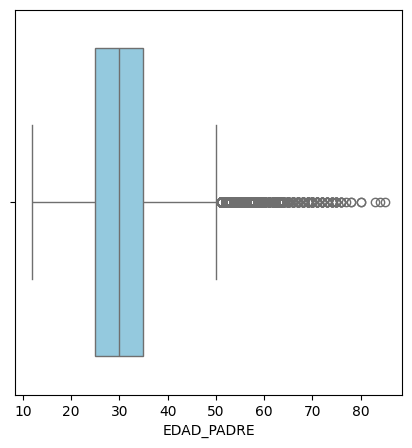

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(5,5))
sns.boxplot(x=df1.EDAD_PADRE, color="skyblue", saturation=0.75)
plt.show()

Se considera que la edad de un padre de un recién nacido en Colombia es atípica si es mayor que 50 años.

El primer cuantil es aproximadamente en 25 años. La media aritmética es de 29 años y el tercel cuantil es aproximadamente de 35 años.
Rango intercuartílico = Tercer cuartil - Primer cuantil = 35 - 25 = 10.

In [ ]:
import plotly.express as px

plt.figure(figsize=(5,5))
fig = px.strip (df1.EDAD_PADRE, orientation= "h")
fig.show()

<Figure size 500x500 with 0 Axes>

De acuerdo con el diagrama de puntos, se observa que la mayoría de edades se concentran entre los 25 y 40 años, mientras que existen pocos valores extremos hacia los 18 y más de 60 años

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
def calcular_estadisticas(datos):
  media = np.mean(datos)
  varianza = np.var(datos)
  asimetria = skew(datos)
  curtosis = kurtosis(datos)
  return media, varianza, asimetria, curtosis

media, varianza, asimetria, curtosis = calcular_estadisticas(df1.EDAD_PADRE)

print(f"Media: {np.mean(df1.EDAD_PADRE)}")
print(f"Varianza: {np.var(df1.EDAD_PADRE)} y la desviación estándar es de {np.std(df1.EDAD_PADRE)}")
print(f"Asimetría: {skew(df1.EDAD_PADRE)}")
print(f"Curtosis: {kurtosis(df1.EDAD_PADRE)}")

Media: 30.399666949841926
Varianza: 59.42512313787833 y la desviación estándar es de 7.708769236258037
Asimetría: 0.7422600985923384
Curtosis: 0.8607555699997431




*   Aproximadamente el promedio de la edad de un padre en Colombia es de 30,4
* Aproximadamente la distancia entre los valores de la edad de un padre y la del número de embarazos es de 7,70

*   Elemento de la lista






La distribucion de la edad padre en Colombia es asimetrica positiva, es decir la media es mayor que la moda de la variable aleatoria

La distribucion es platicurtica es decir hay una baja concentracion de las edades de un padre en Colombia con respecto a la media aritmetica

***Diagrama de dispersion y la recta de regresion para datos bivariados ***

Vamos a determinar si una variable esta correlacionada o depende de otra variable

Una variable depende de la otra cuando la ejecucion de esta se ve afectada por la variable independiente

Una variable esta correlacionada con otra, cuando guardan cierta relacion, pero no es posible hablar de dependencia

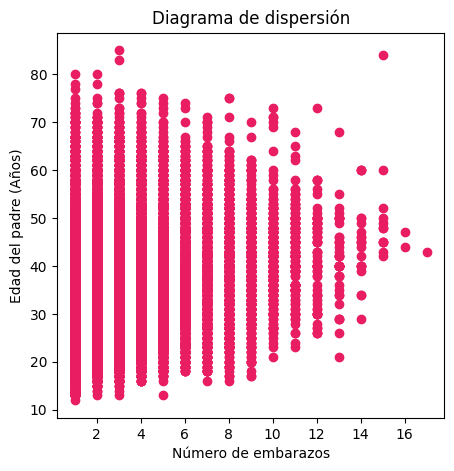

In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt
plt.figure(figsize=(5,5))
plt.scatter (df1['N_EMB'], df1['EDAD_PADRE'], color = "#E91D62", marker = "o")
plt.title("Diagrama de dispersión")
plt.xlabel("Número de embarazos")
plt.ylabel("Edad del padre (Años)")
plt.show()

Se observa en el diagrama de dispersión una nube de puntos sin un patrón particular, esto quiere decir que las variables son independientes o no están correlacionadas. Para nuestro ejemplo quiere decir que la edad de un padre en Colombia y el número de embarazos no están correlacionados.

In [ ]:
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()
modelo.fit(np.array(df1["N_EMB"]).reshape(-1,1), np.array(df1["EDAD_PADRE"]).reshape(-1,1))
predicciones = modelo.predict(np.array(df1["N_EMB"]).reshape(-1,1))
predicciones

array([[30.31494332],
       [32.35070055],
       [32.35070055],
       ...,
       [30.31494332],
       [28.27918608],
       [30.31494332]])

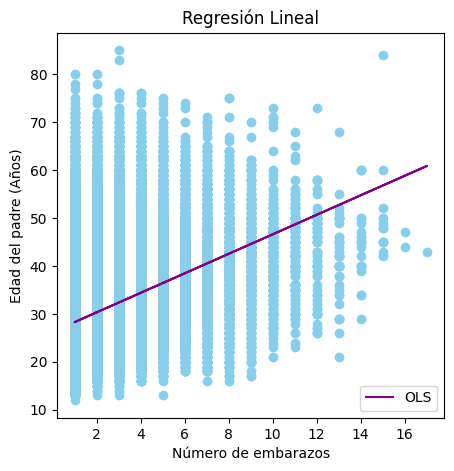

In [ ]:
import plotly.express as px
import matplotlib.pyplot as plt
plt.figure(figsize=(5,5))
plt.scatter (df1['N_EMB'], df1['EDAD_PADRE'], color = "skyblue", marker = "o")
plt.plot(df1["N_EMB"], predicciones, color = "purple", linestyle = "-", label="OLS")
plt.title("Regresión Lineal")
plt.xlabel("Número de embarazos")
plt.ylabel("Edad del padre (Años)")
plt.legend()
plt.show()

De acuerdo con la recta de regresion se determina una correlacion positiva, es decir que entre mas hijos tiene un hombre en Colombia, mas años tiene esta persona

La variable Y depende positivamente de la variable X, es decir entre mayor valor de x se tenga mayor sera el valor de Y

In [ ]:
import numpy as np
from scipy.stats import spearmanr
from scipy.stats import kendalltau

pearson_corr = np.corrcoef(df1["N_EMB"], df1["EDAD_PADRE"])[0,1]
spearman_corr, _ = spearmanr(df1["N_EMB"], df1["EDAD_PADRE"])
kendall_corr, _ = kendalltau(df1["N_EMB"], df1["EDAD_PADRE"])

print("Los coeficientes de correlación son los siguientes: ")
print(f"Correlación de Pearson: {pearson_corr}")
print(f"Correlación de Spearman: {spearman_corr}")
print(f"Correlación de Kendall: {kendall_corr}")

Los coeficientes de correlación son los siguientes: 
Correlación de Pearson: 0.3400379040191506
Correlación de Spearman: 0.36717068310509177
Correlación de Kendall: 0.28723812222507816


Para la interpretacion de los coeficientes de correlacion nos ayudaremos del siguiente articulo de la referencia :

Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. Biometrics, 159–174.

Y depende insignificativamente de X o X y Y están insignificativamente correlacionadas si

X y Y son independientes o no están correlacionadas: $\rho(X,Y) \approx 0,\ \eta(X,Y) \approx 0,\ \kappa(X,Y) \approx 0$

Y depende insignificantemente de X o X y Y están insignificantemente correlacionadas si $0 < |\rho(X,Y)| < 0.2,\ 0 < \eta(X,Y) < 0.2,\ 0 < |\kappa(X,Y)| < 0.2$

Y depende discretamente de X o X y Y están discretamente correlacionadas si $0.2 < |\rho(X,Y)| < 0.4,\ 0.2 < \eta(X,Y) < 0.4,\ 0.2 < |\kappa(X,Y)| < 0.4$

Y depende moderadamente de X o X y Y están moderadamente correlacionadas si $0.4 < |\rho(X,Y)| < 0.6,\ 0.4 < \eta(X,Y) < 0.6,\ 0.4 < |\kappa(X,Y)| < 0.6$

Y depende sustancialmente de X o X y Y están sustancialmente correlacionadas si $0.6 < |\rho(X,Y)| < 0.8,\ 0.6 < \eta(X,Y) < 0.8,\ 0.6 < |\kappa(X,Y)| < 0.8$

Y depende fuertemente de X o X y Y están fuertemente correlacionadas si $0.8 < |\rho(X,Y)| < 1,\ 0.8 < \eta(X,Y) < 1,\ 0.8 < |\kappa(X,Y)| < 1$

De acuerdo con los coeficientes de correlación de Pearson, de Kendall y de Spearman se determina que el número de hijos de un padre y la edad de un padre de un recién nacido en Colombia están discretamente correlacionadas.

**Pregunta 1. ¿Cómo se comporta la variable aleatoria de la edad de un padre de un recién nacido en Colombia (EDAD_PADRE)?**

Sea $X :=$ edad del padre de un recién nacido en Colombia en 2024, con $n = 443.777$ registros tras la limpieza de datos.

**Respuesta:** la edad del padre se concentra en la adultez joven. Su media es de 30,4 años, con una desviación estándar de 7,70 años. El 50 % central de los datos está entre aproximadamente 25 y 35 años ($IQR = 10$), y según el diagrama de puntos la mayoría de las edades se ubica entre los 25 y los 40 años.

La distribución es asimétrica positiva (asimetría = 0,7423): la cola se extiende hacia la derecha y la media es mayor que la moda. Su curtosis es de 0,8608, es decir, es leptocúrtica: los datos se concentran más alrededor de la media que en una distribución normal.

Según la regla de $1.5 \cdot IQR$, son atípicas las edades superiores a 50 años, y se observan pocos valores extremos en padres de aproximadamente 18 años y de más de 60 años.

La variable no tiene distribución normal: la densidad estimada por Kernel no coincide con la curva normal y la prueba de Shapiro-Wilk arrojó un valor p de $7.61 \times 10^{-109} < 0.05$, por lo que se rechaza la normalidad con una confianza del 95 %.

**Conclusión en contexto:** en Colombia la paternidad ocurre principalmente entre los 25 y los 40 años, con pocos padres muy jóvenes y una cola de padres mayores de 50 años.

**2. ¿Cómo se comporta la variable aleatoria del número de embarazos incluido el presente**
(N_EMB)?



In [ ]:
import numpy as np
import pandas as pd
import io
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import skew, kurtosis, shapiro

# Reconstruimos 'tabla' usando la variable 'uploaded' que ya existe en el entorno
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep=",", index_col=0, encoding='latin-1')

df = tabla[["EDAD_PADRE", "N_EMB"]]
df1 = df[(df.EDAD_PADRE < 120) & (df.N_EMB != 99)]
y = df1.N_EMB
print(len(y))

443777


In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis, shapiro

df = tabla[["EDAD_PADRE", "N_EMB"]]
df1 = df[(df.EDAD_PADRE < 120) & (df.N_EMB != 99)]
y = df1.N_EMB

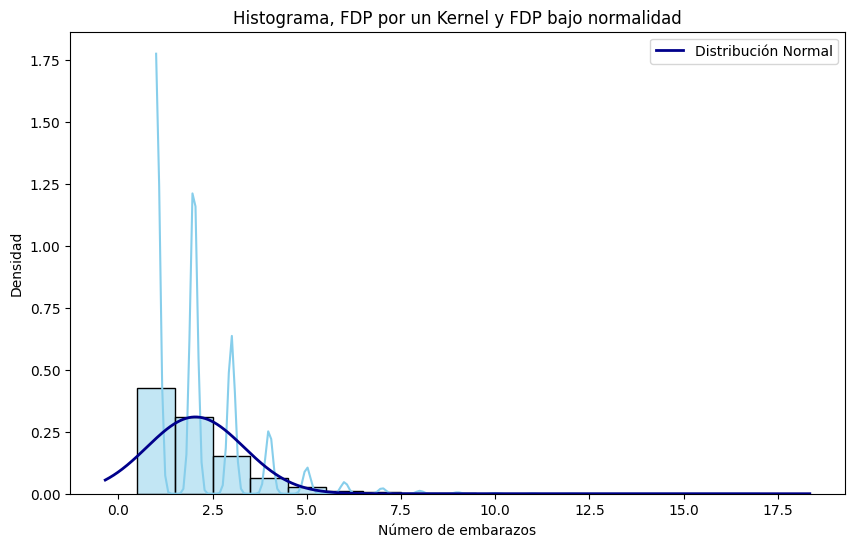

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(x=y, discrete=True, kde=True, stat="density", color="skyblue", edgecolor="black")

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
plt.plot(x, norm.pdf(x, y.mean(), y.std()), color="darkblue", linewidth=2, label="Distribución Normal")

plt.title("Histograma, FDP por un Kernel y FDP bajo normalidad")
plt.xlabel("Número de embarazos")
plt.ylabel("Densidad")
plt.legend()
plt.show()

El histograma muestra que la mayoría de las madres está en su primer o segundo embarazo, con la moda en 1 embarazo. La distribución tiene una cola larga hacia la derecha, es decir, es asimétrica positiva. Como la densidad estimada por un método Kernel no coincide con la función de densidad bajo el supuesto de normalidad, no asumimos normalidad.

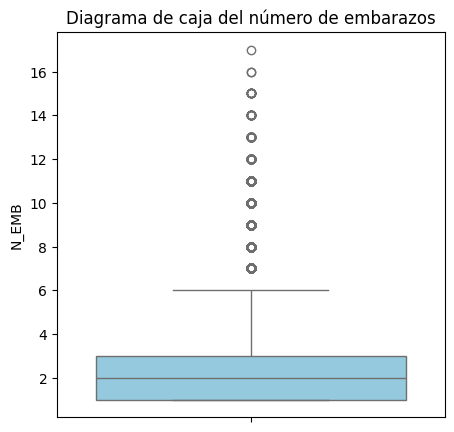

In [ ]:
plt.figure(figsize=(5, 5))
sns.boxplot(y=y, color="skyblue")
plt.title("Diagrama de caja del número de embarazos")
plt.show()

In [ ]:
q1, q3 = y.quantile(0.25), y.quantile(0.75)
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr

print(f"n = {len(y)}")
print(f"Media = {y.mean():.2f} | Mediana = {y.median()} | Moda = {y.mode()[0]}")
print(f"Desv. estándar = {y.std():.2f} | IQR = {iqr} (Q1 = {q1}, Q3 = {q3})")
print(f"Asimetría = {skew(y):.4f} | Curtosis = {kurtosis(y):.4f}")
print(f"Atípicos: valores mayores que {lim_sup}")
print(shapiro(y))

n = 443777
Media = 2.04 | Mediana = 2.0 | Moda = 1
Desv. estándar = 1.29 | IQR = 2.0 (Q1 = 1.0, Q3 = 3.0)
Asimetría = 1.9966 | Curtosis = 6.6058
Atípicos: valores mayores que 6.0
ShapiroResult(statistic=np.float64(0.7612364942886237), pvalue=np.float64(1.61744115214665e-170))


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443777.
  res = hypotest_fun_out(*samples, **kwds)


**Respuesta 2**

Sea $Y :=$ número de embarazos de la madre de un recién nacido en Colombia, incluido el presente, con $n = 443.777$ registros tras la limpieza de datos.

**Respuesta:** el número de embarazos se concentra en valores bajos. La moda es 1 embarazo, la mediana es 2 y la media es de 2,04, con una desviación estándar de 1,29. El 50 % central de los datos está entre 1 y 3 embarazos ($IQR = 2$).

La distribución es asimétrica positiva (asimetría = 1,9966): la cola se extiende hacia la derecha y la media es mayor que la mediana y la moda. Su curtosis es de 6,6058, es decir, es leptocúrtica: los datos se concentran mucho más alrededor de la media que en una distribución normal.

Según la regla de $1.5 \cdot IQR$, son atípicos los valores superiores a 6 embarazos, y el diagrama de caja muestra valores atípicos desde 7 hasta 17 embarazos. Se conservaron porque son valores plausibles para una madre con muchos embarazos.

La variable no tiene distribución normal: el histograma y la densidad estimada por un método Kernel no coinciden con la función de densidad bajo el supuesto de normalidad (que además asigna densidad a valores negativos, imposibles para un conteo), y la prueba de Shapiro-Wilk arrojó un valor p de $1.62 \times 10^{-170} < 0.05$, por lo que se rechaza la normalidad con una confianza del 95 %.

**Conclusión:** en Colombia la mayoría de los nacimientos corresponde a madres en su primer o segundo embarazo, con pocas madres que han tenido muchos embarazos.

**3. ¿Están correlacionadas y qué grado de correlación tienen ambas variables?**

Sean
X el número de embarazos, incluido el presente N_EMB, y Y
la edad del padre de un recién nacido en Colombia (EDAD_PADRE). Para estudiar la relación entre ambas variables, se utiliza un diagrama de dispersión, una recta de regresión lineal y los coeficientes de correlación de Pearson, Spearman y Kendall.

En el diagrama de dispersión se observa una nube de puntos con cierta dispersión, aunque la tendencia general es positiva. Esto indica que, a medida que aumenta el número de embarazos, la edad del padre tiende también a aumentar. Sin embargo, los puntos no siguen una relación lineal perfecta. La recta de regresión lineal presenta una pendiente positiva, lo que muestra una tendencia creciente entre las variables.

Los coeficientes de correlación obtenidos fueron los siguientes:
- Coeficiente de correlación de Pearson:r=0,3400.
Coeficiente de correlación de Spearman: ρ=0,3672.
-Coeficiente de correlación de Kendall: τ=0,2872
El coeficiente de Pearson, de 0.3400, indica una correlación lineal positiva discreta entre las variables. Esto significa que existe una tendencia a que los padres de mayor edad presenten valores más altos en el número de embarazos registrado, aunque la relación lineal no es fuerte.

Por su parte, el coeficiente de Spearman, de 0,3672, también indica una asociación positiva discreta. Este resultado muestra que existe una tendencia creciente entre los rangos de ambas variables. Es importante notar que la diferencia entre Pearson y Spearman sugiere que la relación es ligeramente más monótona que estrictamente lineal, algo esperado al tratar con variables de conteo como el número de embarazos.

El coeficiente de Kendall, de 0,2872, confirma la presencia de una asociación positiva discreta, indicando que existe mayor concordancia que discordancia entre los pares de observaciones de ambas variables.

De acuerdo con los intervalos de interpretación utilizados en el trabajo, los tres coeficientes se encuentran entre 0,2 y 0,4. Por consiguiente, las variables presentan una correlación positiva discreta, es decir, una asociación positiva de magnitud baja a moderada, según el criterio adoptado. No obstante, esta relación estadística no permite afirmar que una variable cause cambios en la otra.

Conclusión : En los registros de nacimientos de Colombia analizados, existe una asociación positiva discreta entre el número de embarazos y la edad del padre. Los tres coeficientes de correlación coinciden en indicar que, a mayores valores del número de embarazos, tienden a observarse mayores edades paternas. Sin embargo, la relación no es especialmente fuerte y no permite afirmar causalidad; estos resultados describen una asociación estadística propia de la base de datos analizada.